# Practical 3F — Sign MNIST Convolutional Autoencoder

Extracted from `3F.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `sign_mnist_test.csv`, `sign_mnist_train.csv`

Normal training images: 26337
Anomaly class: Y (Label 24)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 16)          │           4,624 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 7, 7, 16)            │           2,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d (UpSampling2D)         │ (None, 14, 14, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_1 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 12s 42ms/step - loss: 0.0146 - val_loss: 0.0066
Epoch 2/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 0.0057 - val_loss: 0.0051
Epoch 3/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 0.0048 - val_loss: 0.0044
Epoch 4/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 0.0043 - val_loss: 0.0041
Epoch 5/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 0.0040 - val_loss: 0.0038
Epoch 6/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - loss: 0.0037 - val_loss: 0.0036
Epoch 7/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - loss: 0.0035 - val_loss: 0.0034
Epoch 8/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - loss: 0.0034 - val_loss: 0.0033
Epoch 9/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - loss: 0.0032 - val_loss: 0.0031
Epoch 10/10
186/186 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - loss: 0.0031 - val_loss: 0.0030
Anomaly Threshold: 0.005579546692984377

Confusion Matrix:
[[6470  370]
 [ 302   30]]

Classification Report:
              prec

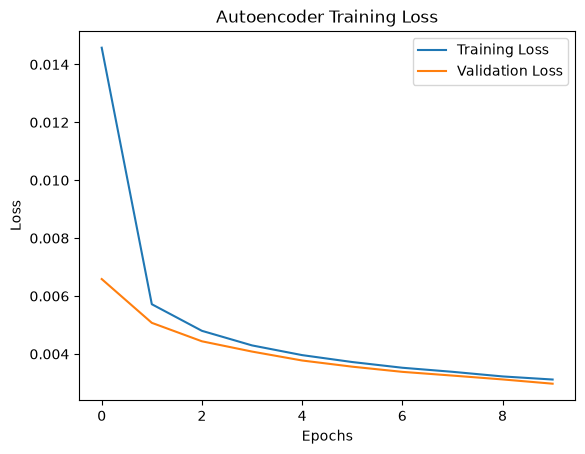

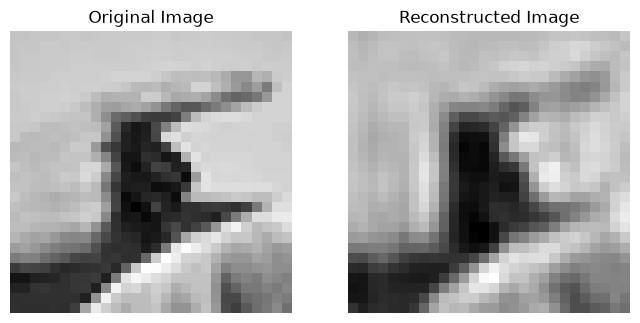

Total Test Images: 7172
Actual Anomalies: 332
Detected Anomalies: 400

Anomaly Detection Completed!


In [2]:
# 1. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
# 2. Load the datasets
train_data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_train.csv')
test_data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/FNN and CNN/Sign Language MNIST/sign_mnist_test.csv')
# 3. Separate images and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values
X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values
# 4. Normalize images
X_train = X_train / 255.0
X_test = X_test / 255.0
# Reshape images into 28x28 grayscale format
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
# Select Y (Label 24) as anomaly
anomaly_label = 24
# Keep only remaining 23 classes for training
X_normal = X_train[y_train != anomaly_label]
print("Normal training images:", len(X_normal))
print("Anomaly class: Y (Label 24)")
# 5. Split normal data into training and validation
X_train_normal, X_val_normal = train_test_split(
    X_normal, test_size=0.1, random_state=42
)
# 6. Build Convolutional Autoencoder
input_img = Input(shape=(28, 28, 1))
# Encoder
x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = MaxPooling2D((2, 2), padding='same')(x)
x = Conv2D(16, (3, 3), activation='relu', padding='same')(x)
encoded = MaxPooling2D((2, 2), padding='same')(x)
# Decoder
x = Conv2D(16, (3, 3), activation='relu', padding='same')(encoded)
x = UpSampling2D((2, 2))(x)
x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = UpSampling2D((2, 2))(x)
decoded = Conv2D(
    1, (3, 3), activation='sigmoid', padding='same'
)(x)
autoencoder = Model(input_img, decoded)
# 7. Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)
autoencoder.summary()
# 8. Train using only normal images
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=128,
    validation_data=(X_val_normal, X_val_normal)
)
# 9. Calculate reconstruction error
val_predictions = autoencoder.predict(X_val_normal, verbose=0)
val_error = np.mean(
    np.square(X_val_normal - val_predictions),
    axis=(1, 2, 3)
)
# Set anomaly threshold
threshold = np.percentile(val_error, 95)
print("Anomaly Threshold:", threshold)
# 10. Detect anomalies in test images
test_predictions = autoencoder.predict(X_test, verbose=0)
test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=(1, 2, 3)
)
# Error above threshold = Anomaly
y_true = (y_test == anomaly_label).astype(int)
y_pred = (test_error > threshold).astype(int)
# 11. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=['Normal', 'Anomaly (Y)'],
    zero_division=0
))
# 12. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
# 13. Display original and reconstructed images
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(X_test[0].reshape(28, 28), cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(test_predictions[0].reshape(28, 28), cmap='gray')
plt.title("Reconstructed Image")
plt.axis('off')
plt.show()
# 14. Display results
print("Total Test Images:", len(y_test))
print("Actual Anomalies:", np.sum(y_true))
print("Detected Anomalies:", np.sum(y_pred))
print("\nAnomaly Detection Completed!")
